In [31]:
import os
import torch
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

# Configurazione base e path (locale o Colab)
csv_path = 'datasets/failure/machine_failure.csv' if os.path.exists('datasets/failure/machine_failure.csv') else 'drive/MyDrive/machine_failure.csv'
window_size = 32
batch_size = 64
features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# 1. Caricamento e Standardizzazione (Fondamentale per la diffusione)
df = pd.read_csv(csv_path)
data_scaled = StandardScaler().fit_transform(df[features].values)

# 2. Creazione Sliding Windows in un'unica riga
# Estraiamo le finestre e facciamo la trasposta (.T) per avere (Canali, Tempo) richiesto da PyTorch 1D
windows = [data_scaled[i : i + window_size].T for i in range(len(data_scaled) - window_size + 1)]

# 3. Creazione del Dataset e DataLoader
dataset = TensorDataset(torch.tensor(windows, dtype=torch.float32))
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Verifica la forma del primo batch generato: [Batch_size, Channels, Window_size]
next(iter(dataloader))[0].shape

# TODO valutare QuantileTransformer per mappare la distribuzione dei dati in una distribuzione Gaussiana, utile per evitare outlier e migliorare la convergenza del modello.

# TODO correggere /tmp/ipykernel_828/3034075615.py:22: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)

torch.Size([64, 5, 32])

In [32]:
import torch
import torch.nn.functional as F
import math

class DDPMScheduler:
    def __init__(self, num_timesteps=300, s=0.008, device="cpu"):
        """
        Inizializza lo scheduler pre-calcolando tutti i parametri del processo di diffusione.
        Usa esclusivamente il Cosine Schedule, ottimale per dati continui/serie temporali.
        Tutti i tensori vengono salvati direttamente nel device corretto.
        """
        self.num_timesteps = num_timesteps
        self.device = device

        # 1. Calcolo del Cosine Beta Schedule
        self.betas = self._cosine_beta_schedule(num_timesteps, s).to(device)

        # 2. Pre-calcolo dei parametri base
        self.alphas = 1.0 - self.betas
        self.alphas_cumprod = torch.cumprod(self.alphas, dim=0)

        # Pad per alphas_cumprod_prev: [1.0, alpha_cumprod[0], alpha_cumprod[1], ...]
        self.alphas_cumprod_prev = F.pad(self.alphas_cumprod[:-1], (1, 0), value=1.0)

        # 3. Pre-calcolo dei termini per il forward process (aggiunta di rumore)
        self.sqrt_alphas_cumprod = torch.sqrt(self.alphas_cumprod)
        self.sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - self.alphas_cumprod)

        # 4. Pre-calcolo della varianza per il reverse process (campionamento)
        self.posterior_variance = self.betas * (1.0 - self.alphas_cumprod_prev) / (1.0 - self.alphas_cumprod)

    def _cosine_beta_schedule(self, timesteps, s):
        """
        Cosine schedule: Evita che il segnale venga distrutto troppo rapidamente nei primi step,
        mantenendo i dettagli a bassa e alta frequenza (come i picchi).
        """
        steps = timesteps + 1
        x = torch.linspace(0, timesteps, steps)
        alphas_cumprod = torch.cos(((x / timesteps) + s) / (1 + s) * math.pi * 0.5) ** 2
        alphas_cumprod = alphas_cumprod / alphas_cumprod[0]

        # betas = 1 - (alpha_bar_t / alpha_bar_{t-1})
        betas = 1.0 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
        return torch.clip(betas, 0.0001, 0.9999)

    def _get_index(self, vals, t, x_shape):
        """
        Estrae il parametro per il timestep t e lo ridimensiona a [B, 1, 1]
        per permettere il broadcasting automatico con x_t [B, C, T].
        """
        batch_size = t.shape[0]
        out = vals.gather(-1, t)

        # Ridimensionamento dinamico in base alle dimensioni di x_shape (es: [B, C, T] -> [B, 1, 1])
        shape = [batch_size] + [1] * (len(x_shape) - 1)
        return out.reshape(shape)

    def add_noise(self, x_0, t, noise=None):
        """
        Esegue il Forward Process calcolando analiticamente q(x_t | x_0):
        x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * noise
        """
        if noise is None:
            noise = torch.randn_like(x_0)

        sqrt_alpha_bar = self._get_index(self.sqrt_alphas_cumprod, t, x_0.shape)
        sqrt_one_minus_alpha_bar = self._get_index(self.sqrt_one_minus_alphas_cumprod, t, x_0.shape)

        x_t = sqrt_alpha_bar * x_0 + sqrt_one_minus_alpha_bar * noise
        return x_t, noise

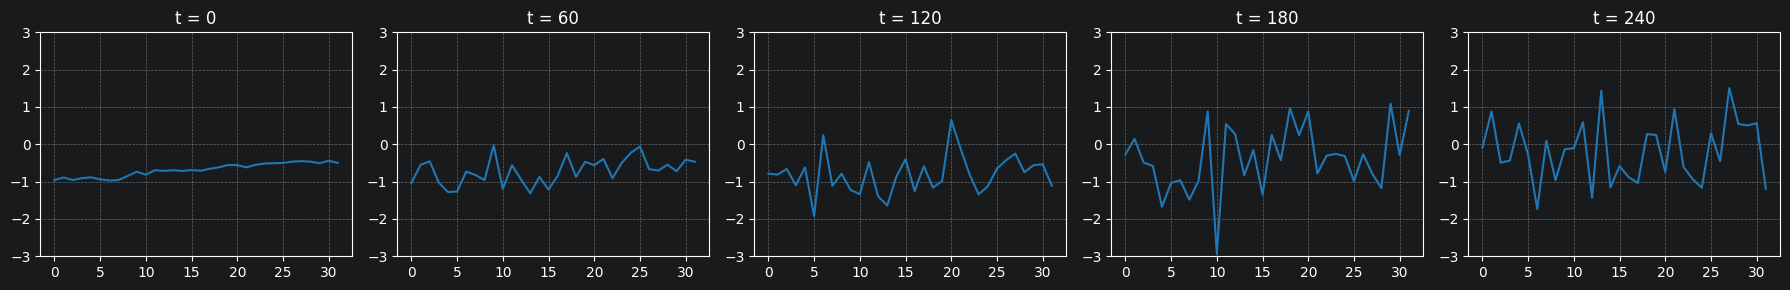

In [33]:
import matplotlib.pyplot as plt
import torch

# 1. Inizializziamo lo scheduler (se non lo avevi già fatto)
scheduler = DDPMScheduler(num_timesteps=300, device="cpu")

# 2. Prendi un campione pulito direttamente dal dataset
# Nota: dataset[0] in un TensorDataset restituisce una tupla (tensor,), quindi prendiamo [0]
x_0 = dataset[0][0]  # Forma (Canali=5, Lunghezza=32)

# Aggiungiamo la batch dimension per compatibilità con lo scheduler
x_0 = x_0.unsqueeze(0)  # Forma -> (1, 5, 32)

plt.figure(figsize=(18, 3))
num_plots = 5
# Calcoliamo lo stepsize usando i parametri dell'oggetto scheduler
stepsize = scheduler.num_timesteps // num_plots

# Generiamo gli indici per i grafici
for i, idx in enumerate(range(0, scheduler.num_timesteps, stepsize)):
    t = torch.tensor([idx], dtype=torch.long)

    # 3. Diffusione usando la nuova sintassi a oggetti
    x_t, noise = scheduler.add_noise(x_0, t)

    # x_t ha forma (1, 5, 32). Facciamo lo squeeze per togliere la dimensione batch.
    # Poi selezioniamo la PRIMA feature ([0], es. 'Air temperature') per non accavallare 5 linee.
    signal = x_t.squeeze(0)[0].cpu().numpy()

    plt.subplot(1, num_plots, i + 1)
    plt.plot(signal, color='tab:blue')

    # 4. Range della Y modificato: -3 a +3 copre il 99.7% di una distribuzione normale (che è il nostro target)
    plt.ylim(-3.0, 3.0)
    plt.title(f"t = {idx}")
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [34]:
import math
import torch
import torch.nn as nn

class SinusoidalPositionEmbeddings(nn.Module):
    """Genera l'embedding posizionale sinusoidale per il timestep t (livello di rumore)."""
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, time: torch.Tensor) -> torch.Tensor:
        device = time.device
        half_dim = self.dim // 2

        emb = math.log(10000.0) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=device, dtype=torch.float32) * -emb)
        emb = time[:, None].float() * emb[None, :]

        embeddings = torch.cat((emb.sin(), emb.cos()), dim=-1)
        return embeddings


class ConvBlock1D(nn.Module):
    """Blocco convoluzionale base 1D con iniezione del timestep.
       Usa GroupNorm e SiLU per stabilità nei modelli a diffusione."""
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()

        # GroupNorm(num_groups, num_channels) sostituisce la BatchNorm
        self.conv1 = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(4, out_ch),
            nn.SiLU(inplace=True)
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.GroupNorm(4, out_ch),
            nn.SiLU(inplace=True)
        )

    def forward(self, x: torch.Tensor, t_emb: torch.Tensor = None) -> torch.Tensor:
        h = self.conv1(x)

        # Iniezione del timestep (broadcasting temporale)
        if t_emb is not None:
            h = h + t_emb.unsqueeze(-1)

        out = self.conv2(h)
        return out


class SimpleUnet1D(nn.Module):
    """U-Net 1D condizionata per Inpainting/Forecasting (DDPM)."""
    def __init__(self, in_channels: int = 11, out_channels: int = 5, time_emb_dim: int = 32):
        super().__init__()

        # --- Time Embedding MLP ---
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU()
        )

        self.time_emb_enc1 = nn.Linear(time_emb_dim, 32)
        self.time_emb_enc2 = nn.Linear(time_emb_dim, 64)
        self.time_emb_bottleneck = nn.Linear(time_emb_dim, 128)
        self.time_emb_dec2 = nn.Linear(time_emb_dim, 64)
        self.time_emb_dec1 = nn.Linear(time_emb_dim, 32)

        # --- Encoder ---
        self.enc1 = ConvBlock1D(in_channels, 32)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)  # T: 32 -> 16

        self.enc2 = ConvBlock1D(32, 64)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)  # T: 16 -> 8

        # --- Bottleneck ---
        self.bottleneck = ConvBlock1D(64, 128)

        # --- Decoder ---
        self.up2 = nn.ConvTranspose1d(128, 64, kernel_size=2, stride=2) # T: 8 -> 16
        # Dopo la concatenazione (64 di up2 + 64 di enc2), in_channels = 128
        self.dec2 = ConvBlock1D(128, 64)

        self.up1 = nn.ConvTranspose1d(64, 32, kernel_size=2, stride=2)  # T: 16 -> 32
        # Dopo la concatenazione (32 di up1 + 32 di enc1), in_channels = 64
        self.dec1 = ConvBlock1D(64, 32)

        # --- Output ---
        self.out_conv = nn.Conv1d(32, out_channels, kernel_size=1)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_emb = self.time_mlp(t)

        # Encoder
        e1 = self.enc1(x, self.time_emb_enc1(t_emb))
        p1 = self.pool1(e1)

        e2 = self.enc2(p1, self.time_emb_enc2(t_emb))
        p2 = self.pool2(e2)

        # Bottleneck
        b = self.bottleneck(p2, self.time_emb_bottleneck(t_emb))

        # Decoder con Skip Connections
        d2 = self.up2(b)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2, self.time_emb_dec2(t_emb))

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1, self.time_emb_dec1(t_emb))

        # Output predice il rumore
        out = self.out_conv(d1)
        return out


# ==========================================
# VERIFICA DEL MODELLO
# ==========================================
if __name__ == "__main__":
    # Parametri operativi
    BATCH_SIZE = 16
    TIME_STEPS = 32
    CHANNELS = 5

    # 5 (xt) + 5 (x_cond) + 1 (mask) = 11
    IN_CHANNELS = CHANNELS * 2 + 1
    OUT_CHANNELS = CHANNELS

    model = SimpleUnet1D(in_channels=IN_CHANNELS, out_channels=OUT_CHANNELS)

    # Simulazione input: (Batch, Canali_Condizionati, Tempo)
    x_input = torch.randn(BATCH_SIZE, IN_CHANNELS, TIME_STEPS)
    t = torch.randint(0, 300, (BATCH_SIZE,)).long()

    output = model(x_input, t)

    print(f"Shape Input  (x_t + x_cond + mask) : {x_input.shape}")
    print(f"Shape Output (rumore predetto eps) : {output.shape}")

    assert output.shape == (BATCH_SIZE, OUT_CHANNELS, TIME_STEPS), "Errore nelle shape in uscita!"
    print("Test architettura superato con successo.")

Shape Input  (x_t + x_cond + mask) : torch.Size([16, 11, 32])
Shape Output (rumore predetto eps) : torch.Size([16, 5, 32])
Test architettura superato con successo.


In [35]:
import torch
import torch.nn.functional as F
import random

def create_dynamic_mask(batch_size, channels, time_steps, device="cpu"):
    """
    Crea dinamicamente maschere [B, 1, T] mescolando Forecasting e Inpainting.
    1: Dati storici/noti
    0: Dati da generare
    """
    mask = torch.ones((batch_size, 1, time_steps), device=device)

    for b in range(batch_size):
        if random.random() < 0.5:
            # Task di FORECASTING (es: ultimi 10-20 step da prevedere su 32)
            split_idx = random.randint(int(time_steps * 0.4), int(time_steps * 0.7))
            mask[b, 0, split_idx:] = 0.0
        else:
            # Task di INPAINTING (es: buco casuale di 8-15 step in mezzo)
            hole_size = random.randint(int(time_steps * 0.25), int(time_steps * 0.5))
            start_idx = random.randint(0, time_steps - hole_size)
            mask[b, 0, start_idx : start_idx + hole_size] = 0.0

    return mask

def get_conditional_loss(model, scheduler, x_0, t):
    """
    Calcola la MSE Loss tra il rumore reale e predetto SOLO sulle porzioni mascherate.
    """
    device = x_0.device
    B, C, T = x_0.shape

    # 1. Forward diffusion tramite lo scheduler (genera rumore su tutta la finestra)
    x_noisy, noise = scheduler.add_noise(x_0, t)

    # 2. Crea la maschera dinamica (Inpainting + Forecasting mischiati)
    mask = create_dynamic_mask(B, C, T, device=device)

    # 3. Prepara x_cond: i dati reali, azzerati dove dobbiamo generare
    # Espandiamo la maschera per tutti i 5 canali (B, C, T)
    mask_expanded = mask.expand(-1, C, -1)
    x_cond = x_0 * mask_expanded

    # 4. Assembla l'input a 11 canali: x_noisy (5) + x_cond (5) + mask (1)
    x_input = torch.cat([x_noisy, x_cond, mask], dim=1)

    # 5. Il modello prevede il rumore
    noise_pred = model(x_input, t)

    # 6. MASKED LOSS: calcoliamo l'errore SOLO dove dobbiamo generare
    # Invertiamo la maschera: 1 sui buchi/futuro, 0 sui dati noti
    target_mask = 1.0 - mask_expanded

    # MSE Loss manuale
    loss = (noise - noise_pred) ** 2
    loss = loss * target_mask

    # Media pesata sui valori effettivamente mascherati per non sballare i gradienti
    final_loss = loss.sum() / (target_mask.sum().clamp(min=1.0))

    return final_loss

In [36]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generate_conditional_trajectory(model, scheduler, x_original, mask):
    """
    Esegue il Reverse Process (Sampling) per ricostruire le parti mancanti di una serie temporale.
    x_original: (B, C, T) I dati originali.
    mask: (B, 1, T) 1 = Dati noti da mantenere, 0 = Dati da prevedere/ricostruire.
    """
    device = x_original.device
    B, C, T_seq = x_original.shape

    # 1. Creiamo x_cond (i dati storici noti, azzerati dove dobbiamo prevedere)
    mask_expanded = mask.expand(-1, C, -1)
    x_cond = x_original * mask_expanded

    # 2. Iniziamo dal puro rumore gaussiano (il canvas vuoto)
    x_t = torch.randn((B, C, T_seq), device=device)

    # 3. Ciclo di Denoising (da T=299 a T=0)
    for i in reversed(range(scheduler.num_timesteps)):
        t = torch.full((B,), i, device=device, dtype=torch.long)

        # A. Assembliamo l'input a 11 canali per la nostra U-Net
        model_input = torch.cat([x_t, x_cond, mask], dim=1)

        # B. La rete predice quale rumore togliere
        noise_pred = model(model_input, t)

        # C. Matematica del DDPM (estratta dallo scheduler)
        alpha_t = scheduler._get_index(scheduler.alphas, t, x_t.shape)
        alpha_cumprod_t = scheduler._get_index(scheduler.alphas_cumprod, t, x_t.shape)
        beta_t = scheduler._get_index(scheduler.betas, t, x_t.shape)

        # Calcolo di x_{t-1} predetto
        model_mean = (1.0 / torch.sqrt(alpha_t)) * (x_t - (beta_t / torch.sqrt(1.0 - alpha_cumprod_t)) * noise_pred)

        if i > 0:
            noise = torch.randn_like(x_t)
            variance = scheduler._get_index(scheduler.posterior_variance, t, x_t.shape)
            x_t_minus_1 = model_mean + torch.sqrt(variance) * noise
        else:
            x_t_minus_1 = model_mean

        # D. FORZATURA DEL CONDIZIONAMENTO (Repaint logic)
        # Sostituiamo le parti che GIA CONOSCIAMO con il segnale reale (aggiungendogli il giusto rumore per il tempo t-1)
        # Questo garantisce che la serie temporale nota non venga alterata dalla generazione.
        if i > 0:
            x_known_noisy, _ = scheduler.add_noise(x_original, t - 1)
        else:
            x_known_noisy = x_original

        x_t = x_t_minus_1 * (1.0 - mask_expanded) + x_known_noisy * mask_expanded

    return x_t


@torch.no_grad()
def plot_forecasting_result(model, scheduler, dataset):
    """
    Test visivo: Prende un campione, ne taglia l'ultima metà e chiede al modello di prevederla.
    """
    model.eval()

    # Prendi un campione dal dataset
    x_real = dataset[0][0].unsqueeze(0) # (1, 5, 32)
    device = next(model.parameters()).device
    x_real = x_real.to(device)

    # Creiamo una maschera per il FORECASTING (primi 16 step noti, ultimi 16 da prevedere)
    mask = torch.zeros((1, 1, 32), device=device)
    mask[:, :, :16] = 1.0

    # Generazione
    x_generated = generate_conditional_trajectory(model, scheduler, x_real, mask)

    # Plot della prima feature (es. Temperatura)
    real_signal = x_real.squeeze(0)[0].cpu().numpy()
    gen_signal = x_generated.squeeze(0)[0].cpu().numpy()

    plt.figure(figsize=(10, 4))
    plt.plot(real_signal, label="Segnale Reale Completo", color='gray', linestyle='dashed', alpha=0.7)
    plt.plot(range(16), real_signal[:16], label="Storico Noto (Condizionamento)", color='blue', linewidth=2)
    plt.plot(range(16, 32), gen_signal[16:], label="Previsione del Modello (Forecasting)", color='red', linewidth=2)

    plt.axvline(x=15.5, color='black', linestyle=':')
    plt.title("Test di Forecasting Condizionato con DDPM")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [37]:
import torch
from torch.optim import AdamW
from torch.utils.data import DataLoader

def train_diffusion_model():
    # ==========================================
    # 1. CONFIGURAZIONE
    # ==========================================
    # Rilevamento automatico della GPU (CUDA per Nvidia, MPS per Mac Apple Silicon, altrimenti CPU)
    if torch.cuda.is_available():
        device = torch.device("cuda")
    elif torch.backends.mps.is_available():
        device = torch.device("mps")
    else:
        device = torch.device("cpu")
    print(f"Dispositivo in uso: {device}")

    # Iperparametri
    EPOCHS = 100
    BATCH_SIZE = 64
    LEARNING_RATE = 1e-4
    TIME_STEPS = 32
    CHANNELS = 5

    # ==========================================
    # 2. INIZIALIZZAZIONE COMPONENTI
    # ==========================================
    # Assumiamo che 'dataset' sia il TensorDataset creato al primo step
    # dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)

    # Inizializziamo Scheduler e Modello
    scheduler = DDPMScheduler(num_timesteps=300, device=device)

    IN_CHANNELS = CHANNELS * 2 + 1  # 11 Canali
    model = SimpleUnet1D(in_channels=IN_CHANNELS, out_channels=CHANNELS).to(device)

    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

    # ==========================================
    # 3. CICLO DI ADDESTRAMENTO
    # ==========================================
    print("Inizio Addestramento...")
    model.train()

    for epoch in range(EPOCHS):
        epoch_loss = 0.0

        for batch in dataloader:
            # Estrarre il tensore dal batch e mandarlo su GPU
            # Forma: (Batch, 5, 32)
            x_0 = batch[0].to(device)
            current_batch_size = x_0.shape[0]

            # 3A. Campionamento casuale del tempo 't' per ogni elemento del batch
            # Questo fa sì che la rete impari a togliere il rumore a tutti i livelli (da 0 a 299)
            t = torch.randint(0, scheduler.num_timesteps, (current_batch_size,), device=device).long()

            # 3B. Calcolo della Loss Mascherata (Inpainting + Forecasting)
            # Ricorda: usa la get_conditional_loss che abbiamo definito nello step precedente!
            loss = get_conditional_loss(model, scheduler, x_0, t)

            # 3C. Backpropagation
            optimizer.zero_grad()
            loss.backward()

            # Gradient clipping (MOLTO UTILE nei modelli a diffusione per evitare esplosioni del gradiente)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()
            epoch_loss += loss.item()

        # 3D. Stampa Statistiche
        media_loss = epoch_loss / len(dataloader)
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoca [{epoch+1}/{EPOCHS}] | Loss Media: {media_loss:.5f}")

    # ==========================================
    # 4. SALVATAGGIO DEL MODELLO
    # ==========================================
    torch.save(model.state_dict(), "diffusion_timeseries_model.pth")
    print("Addestramento completato e modello salvato!")

    return model, scheduler

# ==========================================
# ESECUZIONE
# ==========================================
if __name__ == "__main__":
    # Assicurati di aver definito e caricato il tuo 'dataloader' prima di lanciare questo.
    trained_model, trained_scheduler = train_diffusion_model()
    pass

Dispositivo in uso: cpu
Inizio Addestramento...
Epoca [1/100] | Loss Media: 0.78152
Epoca [10/100] | Loss Media: 0.25102
Epoca [20/100] | Loss Media: 0.21846
Epoca [30/100] | Loss Media: 0.20692
Epoca [40/100] | Loss Media: 0.19978
Epoca [50/100] | Loss Media: 0.19956
Epoca [60/100] | Loss Media: 0.19435
Epoca [70/100] | Loss Media: 0.19183
Epoca [80/100] | Loss Media: 0.19147
Epoca [90/100] | Loss Media: 0.18840
Epoca [100/100] | Loss Media: 0.18676
Addestramento completato e modello salvato!


In [38]:
import matplotlib.pyplot as plt
import torch

# 1. Impostiamo il modello in modalità valutazione (disabilita dropouts, ecc.)
model.eval()

# 2. Preleviamo un campione di test (puoi cambiare l'indice 0 con qualsiasi altro)
# x_real forma: (1, 5, 32)
x_real = dataset[0][0].unsqueeze(0).to(device)

# 3. Creiamo la maschera per il Forecasting (es. 16 step noti, 16 da prevedere)
mask = torch.zeros((1, 1, 32), device=device)
mask[:, :, :16] = 1.0

# 4. Facciamo generare il futuro al modello
# (Usa la funzione generate_conditional_trajectory definita in precedenza)
x_generated = generate_conditional_trajectory(model, scheduler, x_real, mask)

# 5. RIPORTIAMO I DATI AL MONDO REALE (Inverse Transform)
# Passiamo da (1, 5, 32) a (32, 5) perché scikit-learn vuole (Campioni, Feature)
real_scaled = x_real.squeeze(0).cpu().numpy().T
gen_scaled = x_generated.squeeze(0).cpu().numpy().T

# Assicurati che 'scaler' sia l'oggetto QuantileTransformer o RobustScaler creato all'inizio
real_original = scaler.inverse_transform(real_scaled)
gen_original = scaler.inverse_transform(gen_scaled)

# 6. PLOT DEI RISULTATI
# Scegli la feature da plottare (es: 0 = Air temperature, 2 = Rotational speed, 3 = Torque)
feature_idx = 3
feature_name = features[feature_idx]

plt.figure(figsize=(12, 5))

# Disegniamo l'intera traiettoria reale (in grigio tratteggiato) per vedere se ci abbiamo azzeccato
plt.plot(range(32), real_original[:, feature_idx], label="Reale (Ground Truth)", color='gray', linestyle='dashed', alpha=0.7)

# Disegniamo la prima metà (il passato che il modello ha "visto")
plt.plot(range(16), real_original[:16, feature_idx], label="Passato Noto (Condizionamento)", color='tab:blue', linewidth=2.5)

# Disegniamo la seconda metà (il futuro che il modello ha INVENTATO/PREVISTO)
plt.plot(range(16, 32), gen_original[16:, feature_idx], label="Previsione DDPM", color='tab:red', linewidth=2.5)

# Linea di demarcazione
plt.axvline(x=15.5, color='black', linestyle=':', label='Oggi')

plt.title(f"Forecasting Industriale: {feature_name}")
plt.xlabel("Timesteps (T)")
plt.ylabel("Valore Fisico (Originale)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

NameError: name 'device' is not defined